# Step-by-step demo：RGB-D 视频 → 三维特征记忆 → 记忆读取

本 notebook 按[快速验证计划](../docs/research/环境记忆Affordance层_快速验证实验计划_Mac_Isambard_2026-11-05.md)中 **E0（空间投影与数据链路）** 和 **E1（冻结特征与小规模记忆读取）** 的顺序，把当前已实现的每一步单独运行并可视化。

| | 内容 |
|---|---|
| 数据 | Open3D 自带的 Redwood 客厅样例：**合成渲染场景**，5 帧 640×480 RGB-D（含模拟深度噪声）+ RGB-D 里程计估计的相机位姿；11 MB，首次运行自动下载到 `data/open3d/`。**不是 SceneFun3D。** |
| 模型 | 冻结 DINOv2 ViT-S/14（`facebook/dinov2-small`，固定 revision），Mac 上用 MPS。 |
| 记忆 | 3 cm 稀疏体素：位置、颜色、平均视觉特征，以及哪些帧观察过它（来源证据）。 |
| 输出 | 每个 3D 视图另存为 `runs/demo_redwood/*.html`（浏览器可离线打开），指标写入 `metrics.json`。 |

**能说明：** 深度、内参、位姿与像素之间的投影链路是否正确；冻结特征能否按像素写入三维记忆并保留来源帧；记忆能否按特征相似度读取，并区分当前可见、视野外和新观察。

**不能说明：** 这里没有 affordance 标签，也没有训练。查询读取的是普通视觉特征的相似度，对应计划中 C1“普通历史记忆”的机制，不是 affordance 层。样例相机只移动约 10 cm / 3°，真正位于视野外的历史体素很少，不能据此判断历史记忆的价值。这些都要在 SceneFun3D 上按 E0/E1 计划检验。

**运行：** `conda activate affordance3d`，在仓库根目录执行 `jupyter lab notebooks/01_step_by_step_demo.ipynb`，然后 Run All（M1 上约 1 分钟）。3D 图可拖动旋转、滚轮缩放，点击图例可显示/隐藏图层。

## Step 0 · 环境与参数

In [1]:
import json
import sys
import time
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.io as pio

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance3d").is_dir())
sys.path.insert(0, str(ROOT))

from affordance3d.features import DinoV2Extractor, fit_pca_coloring, DINO_ID, DINO_REVISION
from affordance3d.frames import load_redwood_sample
from affordance3d.geometry import backproject, depth_residuals, forward_warp, project
from affordance3d.memory import cosine_scores, coverage, fuse, observe
from affordance3d.viz import frustum_trace, image_row, points_trace, save_html, scene_figure

pio.renderers.default = "plotly_mimetype"  # saved outputs render in JupyterLab / VS Code
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("jpeg")  # photo panels: JPEG keeps the saved notebook small
plt.rcParams["figure.dpi"] = 72
OUT = ROOT / "runs" / "demo_redwood"
OUT.mkdir(parents=True, exist_ok=True)

SAMPLE_STRIDE = 4             # sample every 4th pixel per axis (~1.5 cm apart at 2 m)
VOXEL_SIZE_M = 0.03
DEPTH_TOL_M = 0.05            # visibility test: projected vs observed depth
MEMORY_FRAMES = [0, 1, 2, 3]  # memory is built from this time prefix ...
CURRENT_FRAME = 4             # ... and read from this later view (never written into memory)
QUERIES = {"chair seat": (480, 280), "brick through window": (40, 200), "floor": (300, 440)}  # (u, v) in current frame
TOP_K = 400
FRAME_COLOURS = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]

import torch, open3d, transformers
print(f"python {sys.version.split()[0]} | torch {torch.__version__} (MPS available: {torch.backends.mps.is_available()}) "
      f"| transformers {transformers.__version__} | open3d {open3d.__version__}")
print("outputs ->", OUT.relative_to(ROOT))

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


python 3.12.16 | torch 2.15.0 (MPS available: True) | transformers 5.22.1 | open3d 0.20.0
outputs -> runs/demo_redwood


## Step 1 · 读取 RGB-D 与相机（E0 输入）

每一帧统一成同一个记录：RGB、以米为单位的深度（0 表示无效）、内参 $K$、相机到世界的位姿。之后的步骤只依赖这个记录，换成 SceneFun3D 时只需要换读取函数。

检查项：深度单位（PNG 存的是毫米，这里除以 1000）、图像与深度尺寸一致、位姿方向（camera→world）。

,size (H×W),valid depth,depth range (m),camera position (m)
frame,,,,
0,480×640,87%,0.95 – 2.70,"[2.0, 2.0, -0.3]"
1,480×640,87%,0.98 – 2.70,"[2.0, 1.977, -0.3]"
2,480×640,87%,1.01 – 2.70,"[1.999, 1.954, -0.302]"
3,480×640,87%,1.03 – 2.68,"[1.999, 1.93, -0.303]"
4,480×640,88%,1.05 – 2.70,"[2.001, 1.905, -0.305]"


K =
[[525.    0.  319.5]
 [  0.  525.  239.5]
 [  0.    0.    1. ]]
camera motion frame 0 -> 4: 9.5 cm, 3.0 deg


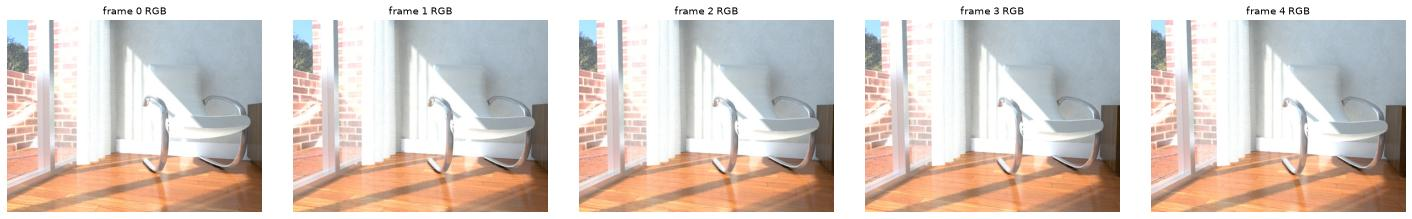

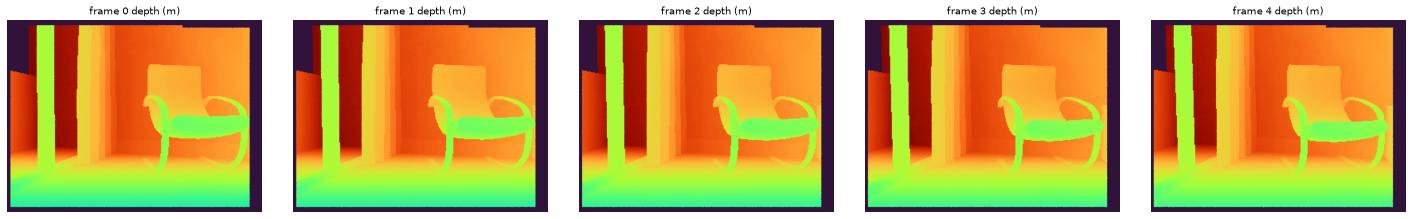

In [2]:
frames = load_redwood_sample(ROOT / "data" / "open3d")
current = frames[CURRENT_FRAME]

display(pd.DataFrame([{
    "frame": f.index,
    "size (H×W)": f"{f.image_hw[0]}×{f.image_hw[1]}",
    "valid depth": f"{(f.depth_m > 0).mean():.0%}",
    "depth range (m)": f"{f.depth_m[f.depth_m > 0].min():.2f} – {f.depth_m.max():.2f}",
    "camera position (m)": np.round(f.cam_to_world[:3, 3], 3).tolist(),
} for f in frames]).set_index("frame"))

relative = np.linalg.inv(frames[0].cam_to_world) @ current.cam_to_world
rotation_deg = np.degrees(np.arccos(np.clip((np.trace(relative[:3, :3]) - 1) / 2, -1, 1)))
print(f"K =\n{frames[0].intrinsics}")
print(f"camera motion frame 0 -> {CURRENT_FRAME}: {np.linalg.norm(relative[:3, 3]) * 100:.1f} cm, {rotation_deg:.1f} deg")

fig, _ = image_row([f.rgb for f in frames], [f"frame {f.index} RGB" for f in frames])
fig.savefig(OUT / "step1_rgb.png", dpi=80)
fig, _ = image_row([f.depth_m for f in frames], [f"frame {f.index} depth (m)" for f in frames], cmap="turbo")
fig.savefig(OUT / "step1_depth.png", dpi=80)
plt.show()

## Step 2 · 单帧反投影：像素 → 三维点

对每个有效深度像素 $(u, v)$：

$$x_w = R_{wc}\,\big(D(u,v)\,K^{-1}[u, v, 1]^\top\big) + t_{wc}$$

与《可行性与实现建议》§2.2 的公式相同。下图是第 0 帧每 2 个像素取 1 个得到的世界坐标点，黑色线框是相机位置和朝向。

In [3]:
points0, pixels0 = backproject(frames[0], stride=2)
colours0 = frames[0].rgb[pixels0[:, 1], pixels0[:, 0]] / 255.0
fig = scene_figure([points_trace(points0, colours0, name="frame 0 points"), frustum_trace(frames[0])],
                   f"Step 2 · frame 0 back-projected ({len(points0):,} points)")
save_html(fig, OUT / "step2_single_frame.html")
fig

## Step 3 · 多帧对齐检查（E0 核心）

三个互相印证的检查：

- **3a 叠加：** 5 帧各自反投影后按帧着色叠在一起；位姿正确时不同颜色互相重合，没有重影或错层。
- **3b 深度残差：** 把第 0 帧的点投影到第 j 帧，比较“投影得到的深度”和“第 j 帧实测深度”。同时设一个**对照组**：故意给第 4 帧用第 0 帧的位姿，模拟“位姿没读对”，确认这个指标真能发现错误。
- **3c 重投影图像：** 用深度和位姿把第 0 帧渲染到第 4 帧的视角，再与真实第 4 帧相减；正确时差异图接近全黑，错误位姿会在边缘处亮起。

In [4]:
traces = []
for f, colour in zip(frames, FRAME_COLOURS):
    pts, _ = backproject(f, stride=SAMPLE_STRIDE)
    traces += [points_trace(pts, colour, name=f"frame {f.index}", size=1.5, max_points=5000),
               frustum_trace(f, colour)]
fig = scene_figure(traces, "Step 3a · all frames overlaid, coloured by frame (aligned = colours coincide)")
save_html(fig, OUT / "step3a_overlay.html")
fig

,points compared,median |Δz| (mm),p90 |Δz| (mm),share < 1 cm
0 → 1,65654,5.2,14.6,77%
0 → 2,64580,5.3,15.5,77%
0 → 3,63686,5.4,15.9,76%
0 → 4,62908,5.6,16.4,75%
0 → 4 WRONG pose (control),66761,40.0,194.0,13%


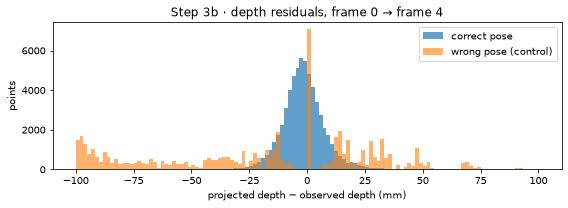

In [5]:
wrong_pose_current = replace(current, cam_to_world=frames[0].cam_to_world)  # deliberate error (control)

def residual_stats(residuals: np.ndarray) -> dict:
    magnitude = np.abs(residuals) * 1000
    return {"points compared": magnitude.size, "median |Δz| (mm)": round(float(np.median(magnitude)), 1),
            "p90 |Δz| (mm)": round(float(np.percentile(magnitude, 90)), 1),
            "share < 1 cm": f"{np.mean(magnitude < 10):.0%}"}

residuals = {f"0 → {f.index}": depth_residuals(frames[0], f, stride=2) for f in frames[1:]}
residuals[f"0 → {CURRENT_FRAME} WRONG pose (control)"] = depth_residuals(frames[0], wrong_pose_current, stride=2)
residual_table = pd.DataFrame({name: residual_stats(r) for name, r in residuals.items()}).T
display(residual_table)

fig, axis = plt.subplots(figsize=(8, 3))
bins = np.linspace(-100, 100, 121)
axis.hist(residuals[f"0 → {CURRENT_FRAME}"] * 1000, bins=bins, alpha=0.7, label="correct pose")
axis.hist(residuals[f"0 → {CURRENT_FRAME} WRONG pose (control)"] * 1000, bins=bins, alpha=0.6, label="wrong pose (control)")
axis.set_xlabel("projected depth − observed depth (mm)"); axis.set_ylabel("points"); axis.legend()
axis.set_title(f"Step 3b · depth residuals, frame 0 → frame {CURRENT_FRAME}")
fig.tight_layout(); fig.savefig(OUT / "step3b_residuals.png", dpi=80)
plt.show()

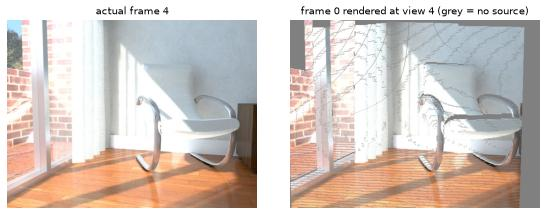

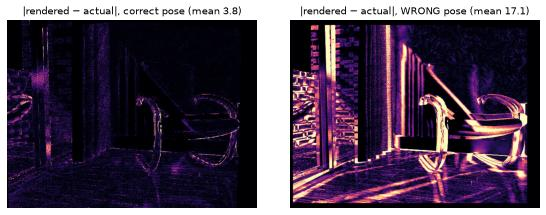

E0 on this sample: median residual 5.6 mm with the recorded poses vs 40.0 mm with the wrong-pose control; no mirroring or scale error is visible.
-> The projection chain works. This says nothing about any learned method.


In [6]:
warped, filled = forward_warp(frames[0], current)
warped_wrong, filled_wrong = forward_warp(frames[0], wrong_pose_current)

def colour_error(rendered: np.ndarray, mask: np.ndarray) -> np.ndarray:
    error = np.abs(rendered.astype(int) - current.rgb.astype(int)).mean(axis=-1)
    return np.where(mask, error, 0.0)

shown = np.where(filled[..., None], warped, 128).astype(np.uint8)  # grey = no source pixel
fig, _ = image_row([current.rgb, shown], [f"actual frame {CURRENT_FRAME}", "frame 0 rendered at view 4 (grey = no source)"])
fig.savefig(OUT / "step3c_warp.png", dpi=80)
error_ok, error_bad = colour_error(warped, filled), colour_error(warped_wrong, filled_wrong)
fig, _ = image_row([error_ok, error_bad],
                   [f"|rendered − actual|, correct pose (mean {error_ok[filled].mean():.1f})",
                    f"|rendered − actual|, WRONG pose (mean {error_bad[filled_wrong].mean():.1f})"],
                   cmap="magma", vmin=0, vmax=60)
fig.savefig(OUT / "step3c_error.png", dpi=80)
plt.show()

ok = residual_table.loc[f"0 → {CURRENT_FRAME}"]["median |Δz| (mm)"]
bad = residual_table.iloc[-1]["median |Δz| (mm)"]
print(f"E0 on this sample: median residual {ok} mm with the recorded poses vs {bad} mm with the wrong-pose control; "
      "no mirroring or scale error is visible.\n-> The projection chain works. This says nothing about any learned method.")

## Step 4 · 冻结 DINOv2 patch 特征（E1 编码器）

整帧缩放到 448×336（不裁剪，保证 patch 与原图位置一一对应），得到 32×24 = 768 个 patch，每个 384 维，对应原图约 20×20 像素。逐帧 batch=1 推理。

为了能“看见”384 维特征，把所有帧的 patch 一起做一次 PCA，取前 3 个主成分当作 RGB。因为是联合拟合，**同一种颜色在不同帧中代表相近的特征**；颜色本身没有语义含义。

W1109 15:17:36.632000 13374 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

device=mps  grid=24x32  dim=384
ms per frame: [732, 60, 60, 61, 63] (the first includes one-off warm-up)


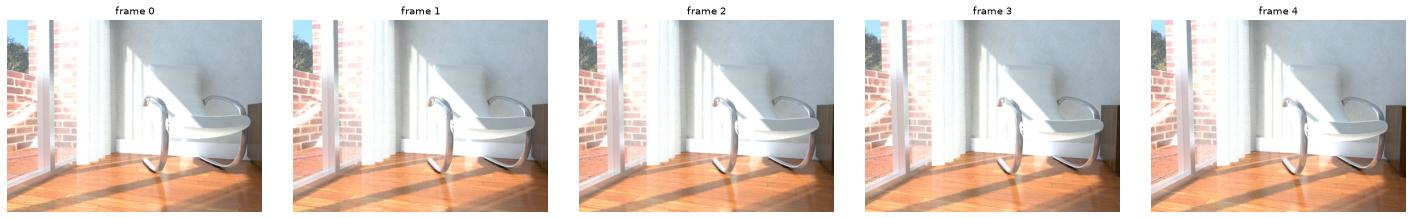

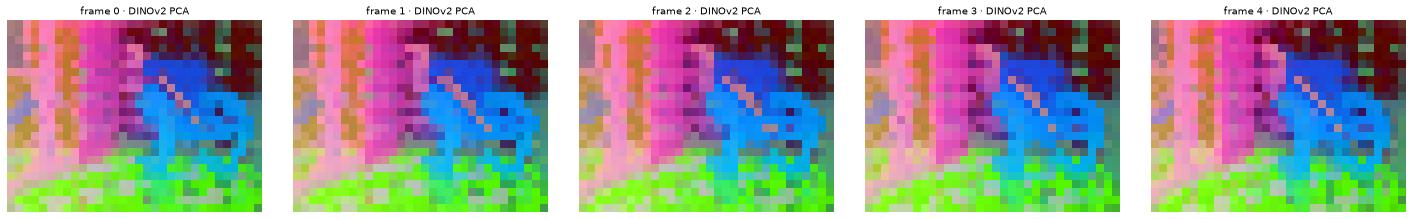

In [7]:
extractor = DinoV2Extractor()
patch_features, seconds = [], []
for f in frames:
    start = time.perf_counter()
    patch_features.append(extractor(f.rgb))
    seconds.append(time.perf_counter() - start)
grid_h, grid_w, dim = patch_features[0].grid.shape
print(f"device={extractor.device}  grid={grid_h}x{grid_w}  dim={dim}")
print("ms per frame:", [round(s * 1000) for s in seconds], "(the first includes one-off warm-up)")

coloring = fit_pca_coloring(np.concatenate([p.grid.reshape(-1, dim) for p in patch_features]))
fig, _ = image_row([f.rgb for f in frames], [f"frame {f.index}" for f in frames])
fig, _ = image_row([coloring.to_rgb(p.grid) for p in patch_features],
                   [f"frame {i} · DINOv2 PCA" for i in range(len(frames))], interpolation="nearest")
fig.savefig(OUT / "step4_features.png", dpi=80)
plt.show()

## Step 5 · 写入三维记忆（只用时间前缀）

只用第 0–3 帧建记忆；第 4 帧作为“当前观察”留给 Step 6–7，**不写入记忆**，避免读到未来。

每个采样像素：反投影得到三维位置 → 取所在 patch 的特征 → 落入 3 cm 体素 → 同一体素内取平均（静态场景下的普通融合基线）→ 记录哪些帧观察过它（来源证据）。

下面的 3D 图默认按真实颜色显示；**点击图例 “DINOv2 feature (PCA)”** 可切换到特征颜色，和 Step 4 的 2D 颜色一致。

In [8]:
observations = [observe(f, p, stride=SAMPLE_STRIDE) for f, p in zip(frames, patch_features)]
memory = fuse([observations[i] for i in MEMORY_FRAMES], VOXEL_SIZE_M)
frames_per_voxel = memory.seen_by.sum(axis=1)

memory_summary = {
    "frames written": str(MEMORY_FRAMES),
    "samples written": sum(len(observations[i].xyz) for i in MEMORY_FRAMES),
    "voxels (3 cm)": memory.n_voxels,
    "memory size (MB)": round(memory.nbytes / 2**20, 1),
    **{f"voxels seen by {k} frame(s)": int((frames_per_voxel == k).sum()) for k in range(1, len(MEMORY_FRAMES) + 1)},
}
display(pd.Series(memory_summary, name="value").to_frame())

fig = scene_figure(
    [points_trace(memory.xyz, memory.rgb, name="colour"),
     points_trace(memory.xyz, coloring.to_rgb(memory.features), name="DINOv2 feature (PCA)", visible="legendonly"),
     *[frustum_trace(frames[i], FRAME_COLOURS[i]) for i in MEMORY_FRAMES]],
    "Step 5 · voxel memory from frames 0–3 (click legend to switch colour / feature view)")
save_html(fig, OUT / "step5_memory.html")
fig

,value
frames written,"[0, 1, 2, 3]"
samples written,66840
voxels (3 cm),8593
memory size (MB),13.0
voxels seen by 1 frame(s),1771
voxels seen by 2 frame(s),1479
voxels seen by 3 frame(s),1576
voxels seen by 4 frame(s),3767


## Step 6 · 当前视角下的覆盖统计

以第 4 帧为当前视角，把记忆中的每个体素分成三类，并统计当前帧中的“新观察”：

| 类别 | 含义 |
|---|---|
| visible now | 记忆中有，当前画面里也看得到 |
| out of view | 记忆中有，但在当前画面外（历史证据） |
| occluded / depth mismatch | 投影在画面内，但深度对不上或缺失：真遮挡；当前帧该像素没有有效深度（右侧和底部的无效深度带）；体素平均位置落在前后两个表面之间（轮廓）；深度噪声 |
| new in current | 当前帧看到、但记忆中从未观察过的位置 |

因为相机移动很小，预计 out of view 只是第 0 帧上、左、下边缘的窄条。new in current 中真正的新内容是第 4 帧右边缘新露出的部分；零散分布在窗帘、窗户和椅子轮廓上的点，多半是深度噪声让采样落进了相邻的空体素，不是新物体。

,voxels,share
visible now,7992,93.0%
out of view,68,0.8%
occluded / depth mismatch,533,6.2%


new in current frame: 495 of 16786 samples (2.9%) fall in voxels the memory never observed


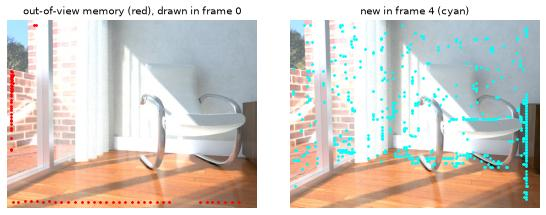

In [9]:
cov = coverage(memory, current, observations[CURRENT_FRAME], DEPTH_TOL_M)
coverage_counts = {"visible now": int(cov.visible_now.sum()), "out of view": int(cov.out_of_view.sum()),
                   "occluded / depth mismatch": int(cov.occluded.sum())}
display(pd.DataFrame({"voxels": coverage_counts,
                      "share": {k: f"{v / memory.n_voxels:.1%}" for k, v in coverage_counts.items()}}))
n_current = len(observations[CURRENT_FRAME].xyz)
print(f"new in current frame: {int(cov.new_in_current.sum())} of {n_current} samples "
      f"({cov.new_in_current.mean():.1%}) fall in voxels the memory never observed")

fig = scene_figure(
    [points_trace(memory.xyz[cov.visible_now], "lightgrey", name="visible now", size=1.5),
     points_trace(memory.xyz[cov.out_of_view], "red", name="out of view", size=4),
     points_trace(memory.xyz[cov.occluded], "orange", name="occluded / depth mismatch", size=3),
     frustum_trace(current, "black")],
    f"Step 6 · memory voxels relative to current frame {CURRENT_FRAME}")
save_html(fig, OUT / "step6_coverage.html")
fig.show()

uv_out, _, inside_out = project(memory.xyz[cov.out_of_view], frames[0])
current_obs = observations[CURRENT_FRAME]
uv_new, _, inside_new = project(current_obs.xyz[cov.new_in_current], current)
fig, axes = image_row([frames[0].rgb, current.rgb],
                      ["out-of-view memory (red), drawn in frame 0", f"new in frame {CURRENT_FRAME} (cyan)"])
axes[0].scatter(uv_out[inside_out, 0], uv_out[inside_out, 1], s=3, c="red")
axes[1].scatter(uv_new[inside_new, 0], uv_new[inside_new, 1], s=3, c="cyan")
fig.savefig(OUT / "step6_coverage.png", dpi=80)
plt.show()

## Step 7 · 记忆读取：用当前画面中的一个 patch 查询记忆（E1 机制）

取第 4 帧某个像素所在 patch 的特征作为查询，与记忆中每个体素的特征算余弦相似度，取最相近的 400 个体素，然后看：

1. 3D 相似度热图（亮 = 相似）；
2. 这些匹配中有多少在当前画面里、多少**只存在于历史中（视野外）**；
3. 来源证据：匹配体素由哪些过去帧观察到；把视野外的匹配画回它们的来源帧。

这是普通视觉特征的相似度读取，用于检验“写入—读取—追溯来源”的机制是否成立；它不代表 affordance 理解。

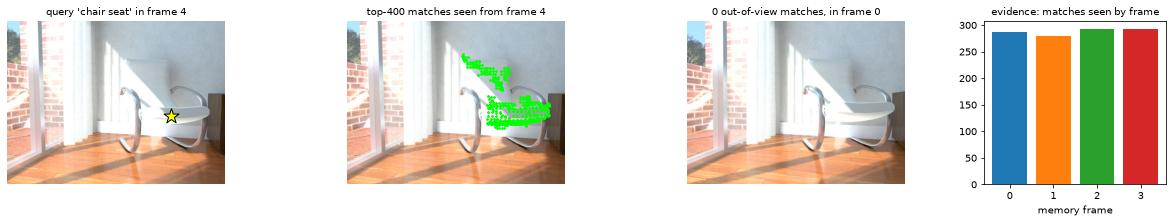

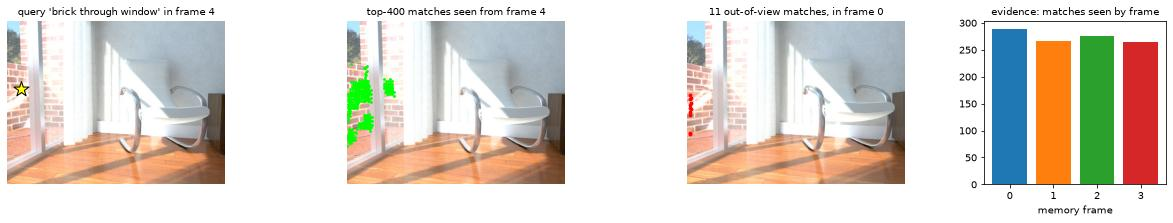

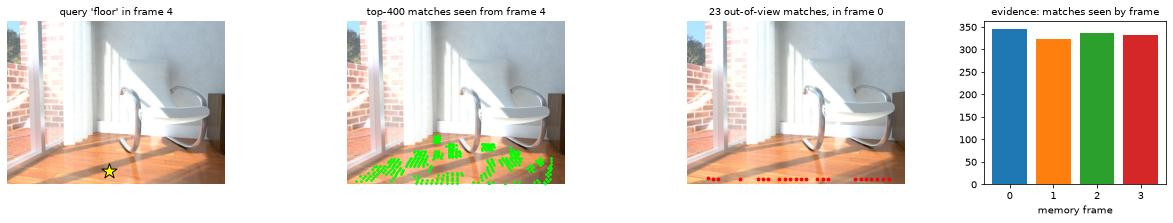

,"pixel (u, v)",best score,score of #400,visible now,out of view,occluded / mismatch
chair seat,"(480, 280)",0.919,0.528,362,0,38
brick through window,"(40, 200)",0.832,0.44,340,11,49
floor,"(300, 440)",0.978,0.666,346,23,31


In [10]:
def show_query(name: str, u: int, v: int, scores: np.ndarray, top: np.ndarray) -> plt.Figure:
    top_out = top[cov.out_of_view[top]]
    evidence = memory.seen_by[top].sum(axis=0)
    source = int(memory.frame_ids[np.argmax(memory.seen_by[top_out].sum(axis=0))]) if len(top_out) else 0
    uv_now, _, in_now = project(memory.xyz[top], current)
    uv_src, _, in_src = project(memory.xyz[top_out], frames[source])

    fig, axes = plt.subplots(1, 4, figsize=(17, 3.2), gridspec_kw={"width_ratios": [4, 4, 4, 2.4]})
    for axis, image, title in [(axes[0], current.rgb, f"query '{name}' in frame {CURRENT_FRAME}"),
                               (axes[1], current.rgb, f"top-{TOP_K} matches seen from frame {CURRENT_FRAME}"),
                               (axes[2], frames[source].rgb, f"{len(top_out)} out-of-view matches, in frame {source}")]:
        axis.imshow(image); axis.set_title(title, fontsize=10); axis.set_axis_off()
    axes[0].scatter([u], [v], s=250, c="yellow", marker="*", edgecolors="black")
    axes[1].scatter(uv_now[in_now, 0], uv_now[in_now, 1], s=3, c="lime")
    axes[2].scatter(uv_src[in_src, 0], uv_src[in_src, 1], s=8, c="red")
    axes[3].bar([str(i) for i in memory.frame_ids], evidence, color=[FRAME_COLOURS[i] for i in memory.frame_ids])
    axes[3].set_title("evidence: matches seen by frame", fontsize=10); axes[3].set_xlabel("memory frame")
    fig.tight_layout()
    return fig

query_results = {}
for name, (u, v) in QUERIES.items():
    query = patch_features[CURRENT_FRAME].at_pixels(np.array([[u, v]]))[0]
    scores = cosine_scores(memory, query)
    top = np.argsort(-scores)[:TOP_K]
    query_results[name] = {
        "pixel (u, v)": (u, v), "best score": round(float(scores.max()), 3),
        f"score of #{TOP_K}": round(float(scores[top[-1]]), 3),
        "visible now": int(cov.visible_now[top].sum()), "out of view": int(cov.out_of_view[top].sum()),
        "occluded / mismatch": int(cov.occluded[top].sum()),
    }
    slug = name.replace(" ", "_")
    fig3d = scene_figure([points_trace(memory.xyz, values=scores, name="cosine similarity", colorscale="Inferno",
                                       cmin=0.0, cmax=1.0),
                          points_trace(memory.xyz[top], "cyan", name=f"top-{TOP_K}", size=3, visible="legendonly"),
                          frustum_trace(current, "white")],
                         f"Step 7 · query '{name}': similarity of every memory voxel")
    fig3d.update_layout(scene_bgcolor="black")
    save_html(fig3d, OUT / f"step7_query_{slug}.html")
    fig3d.show()
    show_query(name, u, v, scores, top).savefig(OUT / f"step7_query_{slug}.png", dpi=80)
    plt.show()

display(pd.DataFrame(query_results).T)

## Step 8 · 汇总与输出

In [11]:
metrics = {
    "data": {"source": "Open3D SampleRedwoodRGBDImages (synthetic living room, odometry poses)",
             "frames": len(frames), "memory_frames": MEMORY_FRAMES, "current_frame": CURRENT_FRAME},
    "config": {"sample_stride": SAMPLE_STRIDE, "voxel_size_m": VOXEL_SIZE_M, "depth_tol_m": DEPTH_TOL_M,
               "model": DINO_ID, "revision": DINO_REVISION, "input_hw": list(extractor.input_hw),
               "device": extractor.device, "torch": torch.__version__},
    "e0_depth_residuals": residual_table.to_dict(orient="index"),
    "features_ms_per_frame": [round(s * 1000, 1) for s in seconds],
    "memory": {k: (v if isinstance(v, (int, float)) else str(v)) for k, v in memory_summary.items()},
    "coverage": {**coverage_counts, "new_in_current": int(cov.new_in_current.sum()), "current_samples": n_current},
    "queries": {k: {kk: (list(vv) if isinstance(vv, tuple) else vv) for kk, vv in q.items()} for k, q in query_results.items()},
}
(OUT / "metrics.json").write_text(json.dumps(metrics, indent=2, ensure_ascii=False, default=int))

e0_median_mm = residual_table.loc[f"0 → {CURRENT_FRAME}", "median |Δz| (mm)"]
display(pd.DataFrame({
    "value": [f"{e0_median_mm} mm",
              f"{np.median(seconds[1:]) * 1000:.0f} ms/frame ({extractor.device})",
              f"{memory.n_voxels:,} voxels, {memory.nbytes / 2**20:.1f} MB",
              f"{coverage_counts['out of view']} voxels ({coverage_counts['out of view'] / memory.n_voxels:.1%})"],
}, index=["E0 median depth residual (0→4)", "DINOv2 ViT-S/14 @448×336", "memory (frames 0–3)",
          "history-only, outside current view"]))
print("saved:", *sorted(p.name for p in OUT.iterdir() if p.suffix in {".html", ".png", ".json"}), sep="\n  ")

,value
E0 median depth residual (0→4),5.6 mm
DINOv2 ViT-S/14 @448×336,60 ms/frame (mps)
memory (frames 0–3),"8,593 voxels, 13.0 MB"
"history-only, outside current view",68 voxels (0.8%)


saved:
  metrics.json
  step1_depth.png
  step1_rgb.png
  step2_single_frame.html
  step3a_overlay.html
  step3b_residuals.png
  step3c_error.png
  step3c_warp.png
  step4_features.png
  step5_memory.html
  step6_coverage.html
  step6_coverage.png
  step7_query_brick_through_window.html
  step7_query_brick_through_window.png
  step7_query_chair_seat.html
  step7_query_chair_seat.png
  step7_query_floor.html
  step7_query_floor.png


### 结论与下一步

**这次运行说明了：** E0 投影链路在样例数据上正确（残差为毫米级，错误位姿对照被明显检出）；冻结 DINOv2 特征在 M1 的 MPS 上可用；特征可以写入带来源帧的三维体素记忆，并能按相似度读取，区分当前可见、视野外和新观察。

**没有说明：** 任何 affordance 能力（没有标签、没有训练）；历史记忆的价值（样例相机几乎不动，视野外部分很少）；真实传感器噪声或跨场景表现。

**下一步（按计划）：**
1. 检查一个 SceneFun3D train/val 序列的包大小，下载 1 个场景的 `hires_wide` / `hires_depth` / `hires_poses` 等资产；
2. 写一个 SceneFun3D 读取函数，输出同样的 `Frame` 记录，本 notebook 的 Step 1–7 即可原样运行，完成 E0（10–20 帧起步）；
3. E1：用开发场景的功能区域 GT 建立原型、在独立视图上读取，区分训练内检查与独立视图诊断。